###1. Libary Setup and Loading
Importing all the required libaries and chack if the GPU is available. We have teh added the liaries for the enitre project over here.

In [1]:
#Edited By: Raynould Joseph
#Date:08/11/2026
import os
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
#importing libs for modal evaluvation
from sklearn.metrics import f1_score, classification_report, confusion_matrix, accuracy_score
from transformers import CLIPProcessor, CLIPModel
from PIL import Image
import matplotlib.pyplot as plt
import time
import warnings
warnings.filterwarnings("ignore")
#changing the code from local runtime to Collab for GPU and faster extreaction
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Currenlty using device:", DEVICE)

Currenlty using device: cuda


Here we have already loaded the libaries and now we are adding the adding as GPU for fater feature and modalling.

###2.Mount Google Drive
Here we are connecting the colab to our google drive so the dataset can loaded from drive each time.

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


This asks for the authorization for mounting. This helps to give data persistance otherwise we need to upload the zip folder with the data after each restart. The mounting is a single step that does  this for us.

###3. unziping the file from the drive
Extracting the folder structures from the zip fileto make the image folder and label files become accessible.

In [3]:
# Change the path if your zip is in a different location
!unzip -q "/content/drive/MyDrive/memotion/memotion_dataset_7k.zip" -d "/content/drive/MyDrive/"

This will create a memotion_dataset_7kfolder with all the respective folders and files. Need to to only do once since the folder are unziped an put in the drive.

###4. Loading and preprocessing Memotion Dataset

Here we are accesssing the files from the dataset and labels into 3 classes Positive, Netural, Negative and using them to handle missing tests and finally dispallying the class distribution for data quality assessment

In [4]:
#loading the path
DATA_DIR = "/content/drive/MyDrive/memotion_dataset_7k"
# accessing different label for different file formats like excel, csv and pickle
if os.path.exists(os.path.join(DATA_DIR, "labels.csv")):
    df = pd.read_csv(os.path.join(DATA_DIR, "labels.csv"))
elif os.path.exists(os.path.join(DATA_DIR, "labels.xlsx")):
    df = pd.read_excel(os.path.join(DATA_DIR, "labels.xlsx"))
else:
    df = pd.read_pickle(os.path.join(DATA_DIR, "labels_pd_pickle"))
#printing the shape and size of the rows.
print("Columns:", df.columns.tolist())
print("Shape:", df.shape)
#taking the columns needed for our task completion
df = df[["image_name", "text_corrected", "overall_sentiment"]].copy()
#making the orginal 5 pionts scale into a 3 point scale
#0 = Postive, 1 = Netural, 2= Negative
sentiment_map = {
    "positive": 0, "very_positive": 0,
    "neutral": 1,
    "negative": 2, "very_negative": 2
}
df["label"] = df["overall_sentiment"].map(sentiment_map)
#doing data cleaning ro remove the missing labels or image names
df = df.dropna(subset=["label", "image_name"])
df["label"] = df["label"].astype(int)
#managing the mising OCR text
df["text"] = df["text_corrected"].fillna("no text").astype(str)
print("\nClass distribution:")
print(df["label"].value_counts(normalize=True).round(3))
print("Total usable samples for modalling :", len(df))

Columns: ['Unnamed: 0', 'image_name', 'text_ocr', 'text_corrected', 'humour', 'sarcasm', 'offensive', 'motivational', 'overall_sentiment']
Shape: (6992, 9)

Class distribution:
label
0    0.595
1    0.315
2    0.090
Name: proportion, dtype: float64
Total usable samples for modalling : 6992


It prints the cloumns names as *Unnamed: 0', 'image_name', 'txt_ocr', 'text_corrected', 'humour', 'sarcasm', 'offensive', 'motivational', 'overall_sentiment'*. Out of these we need only for *image_name", "text_corrected", "overall_sentiment"*.

We take those and have done a small amount of cleaning. The final output we have a class distribution of 59.5% Postive, 31.5% Netural, 9% Negative from the total usuable samples of 6992

###5. Frozen CLIP Feature Extraction
we use the pretrained CLIP model as a forzen feature extractors. For each meme we will have a 512 dimensional image and a 512 dimensional text embeddings. This features are saved and used for training smaller classifiiers

In [5]:
# Cell 3: Frozen CLIP feature extraction
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()

img_feats, txt_feats, labels = [], [], []

for _, row in df.iterrows():
    try:
        img_path = os.path.join(DATA_DIR, "images", row["image_name"])
        img = Image.open(img_path).convert("RGB")
        inputs = processor(text=[row["text"][:200]], images=[img],
                           return_tensors="pt", padding=True, truncation=True)
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
        with torch.no_grad():
            out = clip(**inputs)
        img_feats.append(out.image_embeds.cpu().squeeze())
        txt_feats.append(out.text_embeds.cpu().squeeze())
        labels.append(row["label"])
    except:
        continue

img_feats = torch.stack(img_feats)
txt_feats = torch.stack(txt_feats)
labels = torch.tensor(labels)
print("Features extracted:", img_feats.shape)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Features extracted: torch.Size([6991, 512])


The ouptur shows that CLIP featres were sucessfully extracted from 6991 memes. Each sample now has a 512 dimensional image vector 512 dimensioanl text vector which can be trained for our different modalities.

###6.Stratified Train / Validation / Test Split
Dividing the features into 70% train, 15% validation and 15% test while preserving the class distribution.

In [6]:
#creation of the respective samples
#making the first split 70% and 30% temporary
Ximg_tr, Ximg_tmp, Xtxt_tr, Xtxt_tmp, y_tr, y_tmp = train_test_split(
    img_feats, txt_feats, labels, test_size=0.3, stratify=labels, random_state=42)
#making the temporary validation spilt into 15% validation and 15% test
Ximg_val, Ximg_te, Xtxt_val, Xtxt_te, y_val, y_te = train_test_split(
    Ximg_tmp, Xtxt_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
#make_loader is heper function to create a dataloader from image fetaures, text features and labels
def make_loader(img, txt, y, shuffle=True):
    return DataLoader(TensorDataset(img, txt, y), batch_size=32, shuffle=shuffle)
#making the loader for training, validation, test sets.
train_loader = make_loader(Ximg_tr, Xtxt_tr, y_tr)
val_loader   = make_loader(Ximg_val, Xtxt_val, y_val, False)
test_loader  = make_loader(Ximg_te, Xtxt_te, y_te, False)
print(" 3 type of spliting done.")

 3 type of spliting done.


###7.Model Definitions
Here we define four models for comparision image only, text only , Early Fusion and late fusion. These models will be trained on the forzen features to classify meme sentiment seprately.

This will give a better understanding abour uni modal and muliti modal approaches


In [7]:
#Defining the model defininations
#image-only modal :uses only the CLIP image features
class ImageOnly(nn.Module):
    def __init__(self):
        super().__init__()
        self.head = nn.Linear(512, 3)
    def forward(self, img, txt=None):
        return self.head(img)
#text-only modal:uses only the CLIp text features
class TextOnly(nn.Module):
    def __init__(self):
        super().__init__()
        self.head = nn.Linear(512, 3)
    def forward(self, img, txt):
        return self.head(txt)
#early fusion which combines image and text features and then passes it through MLP
class EarlyFusion(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1024, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 3)
        )
    def forward(self, img, txt):
        return self.net(torch.cat([img, txt], dim=1))
#late fusion seprate classifiers for image and text and then applying the
#weighted combination
class LateFusion(nn.Module):
    def __init__(self):
        super().__init__()
        self.img_head = nn.Linear(512, 3)
        self.txt_head = nn.Linear(512, 3)
        self.w = nn.Parameter(torch.tensor(0.5))
    def forward(self, img, txt):
        w = torch.sigmoid(self.w)
        return w * self.img_head(img) + (1 - w) * self.txt_head(txt)

No printed outout here. these are the structural classes for the modals and ready to be trained in the next cells

###8. Training with early stopping
In this cell we define our traning functions that trains a modal using class-weighted loss to handle imbalance. Here we also uses early stopping based on validation Macro F1 and saves the best modal weights.

In [8]:
def train(model, name, epochs=15, patience=3):
    model = model.to(DEVICE)
    #calculate class weights to handle imbalance
    counts = torch.bincount(y_tr)
    weights = (1.0 / counts.float())
    weights = weights / weights.sum()
    criterion = nn.CrossEntropyLoss(weight=weights.to(DEVICE))
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = {"train_loss": [], "val_f1": []}
    best_f1 = 0
    best_state = None
    wait = 0
    for epoch in range(epochs):
      #Traning phase
        model.train()
        total_loss = 0
        for img, txt, y in train_loader:
            img, txt, y = img.to(DEVICE), txt.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = criterion(model(img, txt), y)
            loss.backward()
            opt.step()
            total_loss += loss.item()
        #Validation phase
        model.eval()
        preds, true = [], []
        with torch.no_grad():
            for img, txt, y in val_loader:
                out = model(img.to(DEVICE), txt.to(DEVICE))
                preds += out.argmax(1).cpu().tolist()
                true  += y.tolist()
        val_f1 = f1_score(true, preds, average="macro")
        #recording phase
        history["train_loss"].append(total_loss / len(train_loader))
        history["val_f1"].append(val_f1)
        #early stop check by comparing the f1 score
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = model.state_dict().copy()
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break
        print(f"{name:12s} Epoch {epoch+1:2d} | Val Macro-F1: {val_f1:.4f}")
    #Saving the best weights
    model.load_state_dict(best_state)
    torch.save(best_state, f"best_{name}.pt")
    return model, history

Here their is nothing to dispay we are saving all the trained metrics and printing them for later.

 ###9. Train All Models
 We train all the models
 1. image-only
 2. Text only
 3. Early fusion
 4. Late fusion
 Each modal is taried with help of early stopping and the best weights are saved.


In [9]:
# Here we are training all the models and storing their traning history
models = {
    "image": ImageOnly(),
    "text":  TextOnly(),
    "early": EarlyFusion(),
    "late":  LateFusion()
}
histories = {}
for name, model in models.items():
    print(f"\n=== Training {name.upper()} ===")
    models[name], histories[name] = train(model, name)


=== Training IMAGE ===
image        Epoch  1 | Val Macro-F1: 0.3160
image        Epoch  2 | Val Macro-F1: 0.3203
image        Epoch  3 | Val Macro-F1: 0.3362
image        Epoch  4 | Val Macro-F1: 0.3498
image        Epoch  5 | Val Macro-F1: 0.3378
image        Epoch  6 | Val Macro-F1: 0.3515
image        Epoch  7 | Val Macro-F1: 0.3455
image        Epoch  8 | Val Macro-F1: 0.3463
image        Epoch  9 | Val Macro-F1: 0.3575
image        Epoch 10 | Val Macro-F1: 0.3484
image        Epoch 11 | Val Macro-F1: 0.3515
Early stopping at epoch 12

=== Training TEXT ===
text         Epoch  1 | Val Macro-F1: 0.3156
text         Epoch  2 | Val Macro-F1: 0.3271
text         Epoch  3 | Val Macro-F1: 0.3397
text         Epoch  4 | Val Macro-F1: 0.3421
text         Epoch  5 | Val Macro-F1: 0.3638
text         Epoch  6 | Val Macro-F1: 0.3481
text         Epoch  7 | Val Macro-F1: 0.3465
Early stopping at epoch 8

=== Training EARLY ===
early        Epoch  1 | Val Macro-F1: 0.1844
early        Epoch  2

The output depicts the validation Macro F1 for each of every model. Early stoping is trigereed when score stops improving. From the above results text-only and late fusion acheived teh highest validation score.

###9.Final evaluation
Here we evaluting all the tranied models on the test set. We use Accuracy and Macro F1 as the main metrics. Macro F1 is perfered because the dataset is imbalanced and trusting alone can misleading. We also print the classification report and confusion metrix to see teh performance on each emotion class and used training curves to check for overfitting

###


===== IMAGE TEST =====
Accuracy: 0.3985 | Macro F1: 0.3311
              precision    recall  f1-score   support

    Positive       0.61      0.37      0.46       624
     Neutral       0.34      0.52      0.41       331
    Negative       0.10      0.17      0.12        94

    accuracy                           0.40      1049
   macro avg       0.35      0.35      0.33      1049
weighted avg       0.48      0.40      0.41      1049

Confusion Matrix:
 [[231 293 100]
 [110 171  50]
 [ 36  42  16]]

===== TEXT TEST =====
Accuracy: 0.4175 | Macro F1: 0.3279
              precision    recall  f1-score   support

    Positive       0.58      0.47      0.52       624
     Neutral       0.31      0.40      0.35       331
    Negative       0.10      0.13      0.11        94

    accuracy                           0.42      1049
   macro avg       0.33      0.33      0.33      1049
weighted avg       0.45      0.42      0.43      1049

Confusion Matrix:
 [[293 258  73]
 [167 133  31]
 [ 45

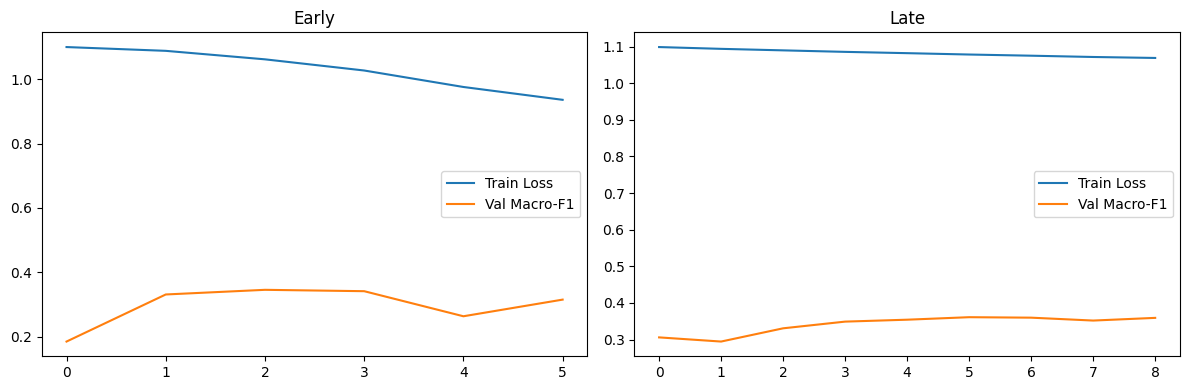


=== Summary Macro F1 ===
image     : 0.3311
text      : 0.3279
early     : 0.3145
late      : 0.3544


In [10]:
#doing the accuracy, F1 macro score to Visualize the results
def evaluate(model, name):
    model.load_state_dict(torch.load(f"best_{name}.pt"))
    model.eval()
    preds, true = [], []
    with torch.no_grad():
        for img, txt, y in test_loader:
            out = model(img.to(DEVICE), txt.to(DEVICE))
            preds += out.argmax(1).cpu().tolist()
            true  += y.tolist()
    #calcualitng the metrics using confusion metrics
    acc = accuracy_score(true, preds)
    #using the macro score for the imbalanced data
    macro_f1 = f1_score(true, preds, average="macro")
    print(f"\n===== {name.upper()} TEST =====")
    print(f"Accuracy: {acc:.4f} | Macro F1: {macro_f1:.4f}")
    print(classification_report(true, preds, target_names=["Positive","Neutral","Negative"]))
    print("Confusion Matrix:\n", confusion_matrix(true, preds))
    return macro_f1
results = {}
for name in models:
    results[name] = evaluate(models[name], name)
# drawing the training curves to check overfiting
plt.figure(figsize=(12, 4))
for i, name in enumerate(["early", "late"]):
    plt.subplot(1, 2, i+1)
    plt.plot(histories[name]["train_loss"], label="Train Loss")
    plt.plot(histories[name]["val_f1"], label="Val Macro-F1")
    plt.title(name.capitalize())
    plt.legend()
plt.tight_layout()
plt.savefig("overfitting_curves_and traning_curves.png")
plt.show()

print("\n=== Summary Macro F1 ===")
for name, f1 in results.items():
    print(f"{name:10s}: {f1:.4f}")

In [1]:
# Clone your repository
!git clone https://github.com/rj20000/multiModalAssignment.git
%cd multiModalAssignment

Cloning into 'multiModalAssignment'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.
/content/multiModalAssignment


In [ ]:
!find /content/drive -name "*.ipynb" 2>/dev/null

In [ ]:
!cp "/content/drive/MyDrive/Colab Notebooks/a1947703_raynouldJosephAssignmentFile.ipynb" /content/multiModalAssignment/